## Initial Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
warriorsData = pd.read_excel("Case Study 2 Data.xlsx", sheet_name="warriors_data")

##print(warriorsData.head())
#print(warriorsData.info())

In [ ]:
customer_levels = ["Last-Minute", "In-Between", "Planner"]

warriorsData['Customer_Type'] = pd.Categorical(
    warriorsData['Customer_Type'],
    categories=customer_levels,
    ordered=True
)

#print(warriorsData.head())

#print(warriorsData.info()) #one categorical category added

In [4]:
warriorsData.columns

Index(['customerID', 'customerName', 'Age', 'Fan_Mailing_List',
       'Customer_Type', 'Game_ID', 'Num_Tickets_Purchased', 'Seat_Location',
       'Ticket_Price', 'Concession_Purchases', 'Days_Before_Game'],
      dtype='object')

In [5]:
num_rows = warriorsData.shape[0]
num_cols = warriorsData.shape[1]

print(f"\nNumber of Rows: {num_rows}")
print(f"Number of Columns: {num_cols}")

total_missing_values = warriorsData.isna().sum().sum()
print(f"\nTotal Missing Values: {total_missing_values}")


Number of Rows: 1000
Number of Columns: 11

Total Missing Values: 0


In [6]:
print(warriorsData['Days_Before_Game'].describe())

count    1000.000000
mean       11.087000
std        10.047706
min         0.000000
25%         2.000000
50%         9.000000
75%        19.000000
max        36.000000
Name: Days_Before_Game, dtype: float64


## Estimating the number of days before a game a customer is likely to purchase a ticket

### GSW Attempt

#### Part 1: Simple linear regression model

## Simple Regression Equation ##
Days_Before_Game = -14.59023 + 0.59413 * Age


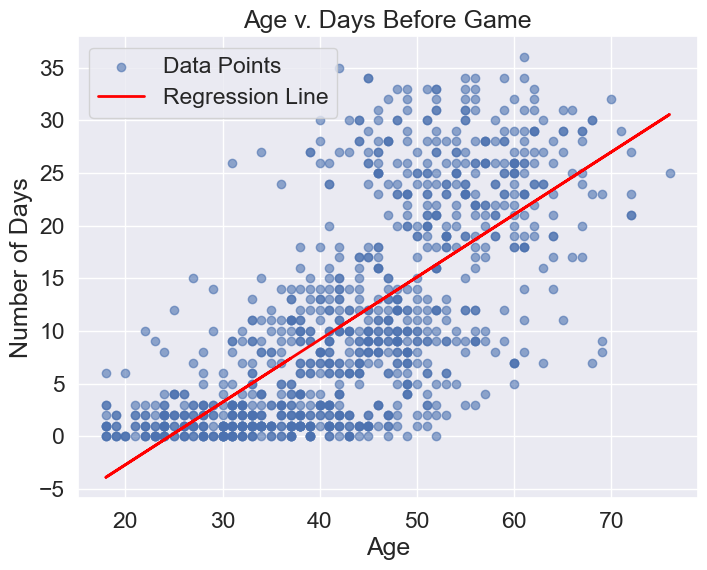

In [49]:
from sklearn.linear_model import LinearRegression
warriorsData = pd.read_excel("Case Study 2 Data.xlsx", sheet_name="warriors_data")

customer_levels = ["Last-Minute", "In-Between", "Planner"]


warriorsData['Customer_Type'] = pd.Categorical(
    warriorsData['Customer_Type'],
    categories=customer_levels,
    ordered=True
)


# features
X_simple = warriorsData[['Age']]
y = warriorsData['Days_Before_Game']


modelLMSimple = LinearRegression()
modelLMSimple.fit(X_simple, y)


intercept_simple = modelLMSimple.intercept_
coef_simple = modelLMSimple.coef_[0]

print("## Simple Regression Equation ##")
print(f"Days_Before_Game = {intercept_simple:.5f} + {coef_simple:.5f} * Age")
#simple_prediction = modelLMSimple.predict(X_test_simple)
#potting
plt.figure(figsize=(8, 6))
plt.scatter(X_simple, y, alpha=0.6, label='Data Points')
plt.plot(X_simple, modelLMSimple.predict(X_simple), color='red', linewidth=2, label='Regression Line')
plt.title('Age v. Days Before Game')
plt.xlabel('Age')
plt.ylabel('Number of Days')
plt.legend()
plt.grid(True)
plt.show()



#### Part 2: Multiple Linear Regression Model

In [ ]:
features = ['Ticket_Price', 'Num_Tickets_Purchased', 'Seat_Location', 'Age', 'Fan_Mailing_List']
X_multiple = warriorsData[features].copy()

#nrmapping
fan_col = (
    X_multiple['Fan_Mailing_List']
        .astype(str).str.strip().str.lower()
        .map({
            'yes': 1, 'y': 1, 
            'no': 0,  'n': 0
        })
)

# default to 0
X_multiple['Fan_Mailing_List'] = fan_col.fillna(0).astype(int)

# Onehot encode
X_multiple = pd.get_dummies(X_multiple, columns=['Seat_Location'], drop_first=True)


for col in ['Ticket_Price', 'Num_Tickets_Purchased', 'Age']:
    X_multiple[col] = pd.to_numeric(X_multiple[col], errors='coerce')

X_multiple = X_multiple.dropna()


y_aligned = y.loc[X_multiple.index]

modelLMMultiple = LinearRegression()
modelLMMultiple.fit(X_multiple, y_aligned)

#display like in their R code
print("\n## Multiple Regression Model Coefficients ##")
print(f"Intercept: {modelLMMultiple.intercept_:.5f}")
coeffs = pd.Series(modelLMMultiple.coef_, index=X_multiple.columns)
print("Coefficients:")
print(coeffs)



## Multiple Regression Model Coefficients ##
Intercept: -9.64670
Coefficients:
Ticket_Price            -0.001539
Num_Tickets_Purchased    1.542508
Age                      0.411451
Fan_Mailing_List         2.953655
Seat_Location_Upper     -3.268948
dtype: float64


### My RandomForestRegressor to estimate the number of days before a customer buys ticket

In [19]:
warriorsData = pd.read_excel("Case Study 2 Data.xlsx", sheet_name="warriors_data")

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score

In [20]:
#predict days before game
y = warriorsData['Days_Before_Game']


#PREVENT DATA LEAKAGE SO DROP CUSTOMER TYPE FS
features_to_drop = ['Days_Before_Game', 'customerID', 'customerName', 'Game_ID', 'Customer_Type',]
X = warriorsData.drop(columns=features_to_drop)

print(X.columns.tolist())

['Age', 'Fan_Mailing_List', 'Num_Tickets_Purchased', 'Seat_Location', 'Ticket_Price', 'Concession_Purchases']


In [ ]:
#80% training, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [23]:
categorical_features = ['Fan_Mailing_List', 'Seat_Location']
numerical_features = ['Age', 'Num_Tickets_Purchased', 'Ticket_Price', 'Concession_Purchases']

#handle other type!
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough' 
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

#training
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Fan_Mailing_List',
                                                   'Seat_Location'])])),
                ('regressor', RandomForestRegressor(random_state=42))])

In [28]:
#do predicted days before game
y_pred = model_pipeline.predict(X_test)

#metrics
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared: {r2:.2f}")

Mean Absolute Error (MAE): 3.88
R-squared: 0.67


### Check on the same warriorsnewdata as GSW

In [48]:
#check on warriors new
feature_columns = X.columns.tolist() 
X_new = warriorsDataNew[feature_columns]


print(X_new.columns.tolist())

# use on this new small dataset
new_predictions = model_pipeline.predict(X_new)

results_df = warriorsDataNew[['customerID', 'Age', 'Seat_Location', 'Days_Before_Game']].copy()
results_df['Predicted_Days'] = new_predictions

print("\nRFR Prediction Results on warriorsnewdata")
print(results_df)

['Age', 'Fan_Mailing_List', 'Num_Tickets_Purchased', 'Seat_Location', 'Ticket_Price', 'Concession_Purchases']

RFR Prediction Results on warriorsnewdata
         customerID  Age Seat_Location  Days_Before_Game  Predicted_Days
0  13a19a2d8c0c6df2   52         Lower                28             2.0
1  549329135798fb72   33         Upper                 1             0.0
2  881b0abac250e536   50         Upper                 3             1.0
3  1bd5437a8b98bff3   48         Lower                 7             1.0
4  cb41912524b8b601   48         Lower                21             1.0


## Classifying Customer Type

### GSW Attempt

In [32]:
warriorsData = pd.read_excel("Case Study 2 Data.xlsx", sheet_name="warriors_data")


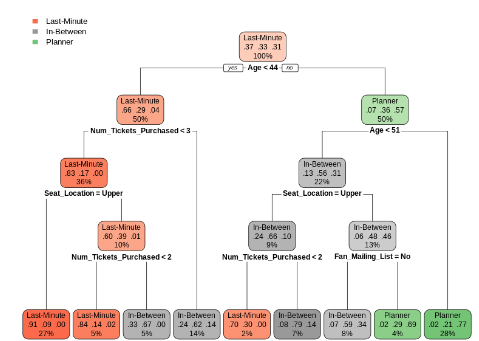

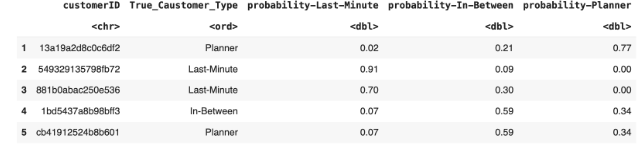

### My Gradeint Boosting Model to classify customer category

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report



warriorsData = pd.read_excel("Case Study 2 Data.xlsx", sheet_name="warriors_data")
features_to_drop = ['Customer_Type', 'customerID', 'customerName', 'Game_ID', 'Days_Before_Game']
X = warriorsData.drop(columns=features_to_drop)
y = warriorsData['Customer_Type']

#encode with order this time
category_order = ['Last-Minute', 'In-Between', 'Planner']
ordinal_encoder = OrdinalEncoder(categories=[category_order])
y_encoded = ordinal_encoder.fit_transform(y.values.reshape(-1, 1)).flatten()


In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

In [36]:
categorical_features = ['Fan_Mailing_List', 'Seat_Location']
numerical_features = ['Age', 'Num_Tickets_Purchased', 'Ticket_Price', 'Concession_Purchases']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough' 
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(n_estimators=100, random_state=42))
])

#training
model_pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Fan_Mailing_List',
                                                   'Seat_Location'])])),
                ('classifier', GradientBoostingClassifier(random_state=42))])

In [38]:
y_pred = model_pipeline.predict(X_test)

# convert back into words 
target_names = ordinal_encoder.categories_[0]


print("\nGBM Model Results")
print(classification_report(y_test, y_pred, target_names=target_names))


GBM Model Results
              precision    recall  f1-score   support

 Last-Minute       0.93      0.88      0.90        74
  In-Between       0.71      0.74      0.72        65
     Planner       0.81      0.82      0.81        61

    accuracy                           0.81       200
   macro avg       0.81      0.81      0.81       200
weighted avg       0.82      0.81      0.82       200



## Extra figures

Revenue by tickets and concessions:
  Customer_Type        Revenue_Type  Total_Revenue
0    In-Between      Ticket_Revenue      294362.65
1   Last-Minute      Ticket_Revenue      146685.06
2       Planner      Ticket_Revenue      403195.31
3    In-Between  Concession_Revenue        4725.53
4   Last-Minute  Concession_Revenue        1223.52
5       Planner  Concession_Revenue        7570.61


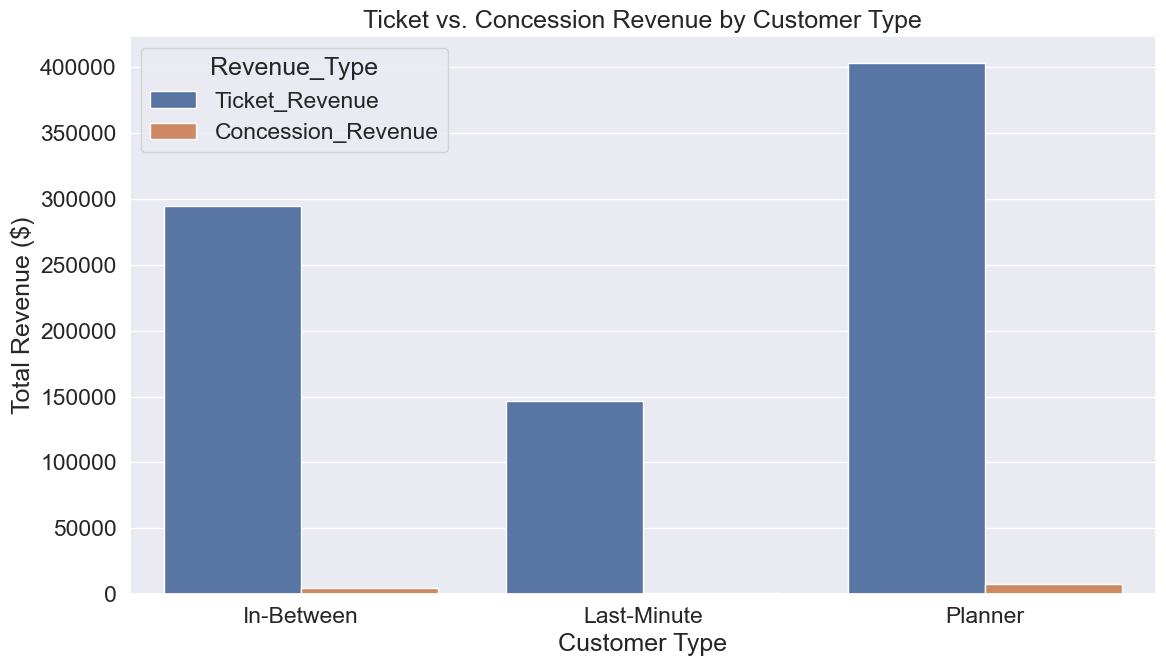

Current num of 'Planners': 306
Average total revenue per 'Planner': $1,342.37
A 10% increase represents 30.6 new customers.
----------------------------------------
Projected revenue increase from those planner customers: $41,076.59


In [42]:
#revenue by customer type
warriorsData = pd.read_excel("Case Study 2 Data.xlsx", sheet_name="warriors_data")

#find revenue and concession ticket revenue
warriorsData['Ticket_Revenue'] = warriorsData['Ticket_Price'] * warriorsData['Num_Tickets_Purchased']


#organize by customer
revenue_by_category = warriorsData.groupby('Customer_Type').agg(
    Ticket_Revenue=('Ticket_Revenue', 'sum'),
    Concession_Revenue=('Concession_Purchases', 'sum')
).reset_index()


revenue_melted = pd.melt(revenue_by_category,
                         id_vars='Customer_Type',
                         value_vars=['Ticket_Revenue', 'Concession_Revenue'],
                         var_name='Revenue_Type',
                         value_name='Total_Revenue')

print("Revenue by tickets and concessions:")
print(revenue_melted)
sns.set_theme(font_scale=1.5)


plt.figure(figsize=(12, 7))
sns.barplot(data=revenue_melted, x='Customer_Type', y='Total_Revenue', hue='Revenue_Type')

#designing
plt.xlabel("Customer Type")
plt.ylabel("Total Revenue ($)")
plt.title("Ticket vs. Concession Revenue by Customer Type")
#plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



warriorsData['Total_Revenue'] = (warriorsData['Ticket_Price'] * warriorsData['Num_Tickets_Purchased']) + warriorsData['Concession_Purchases']

planners_df = warriorsData[warriorsData['Customer_Type'] == 'Planner'].copy()

#math to find how much increase with 10% more plannes
num_planners = len(planners_df)
total_planner_revenue = planners_df['Total_Revenue'].sum()

#average revenue per planner
avg_revenue_per_planner = total_planner_revenue / num_planners

# number of new customers, 10% more
num_new_planners = num_planners * 0.10
projected_revenue_increase = num_new_planners * avg_revenue_per_planner


#resuts
print(f"Current num of 'Planners': {num_planners}")
print(f"Average total revenue per 'Planner': ${avg_revenue_per_planner:,.2f}")
print(f"A 10% increase represents {num_new_planners:.1f} new customers.")
print("-" * 40)
print(f"Projected revenue increase from those planner customers: ${projected_revenue_increase:,.2f}")




In [44]:
#Seating Preference by Customer Type

deck_data = warriorsData[warriorsData['Seat_Location'].isin(['Upper', 'Lower'])]


#organized yb percents
seat_preference_pct = pd.crosstab(deck_data['Customer_Type'],
                                  deck_data['Seat_Location'],
                                  normalize='index') * 100


print("Seating Preference by Customer Type (%)")
print(seat_preference_pct.round(2))

Seating Preference by Customer Type (%)
Seat_Location  Lower  Upper
Customer_Type              
In-Between     53.99  46.01
Last-Minute    19.57  80.43
Planner        75.16  24.84


Average Spend by whether on mailing list
  Fan_Mailing_List  Total_Revenue
0               No     777.715683
1              Yes    1076.398507


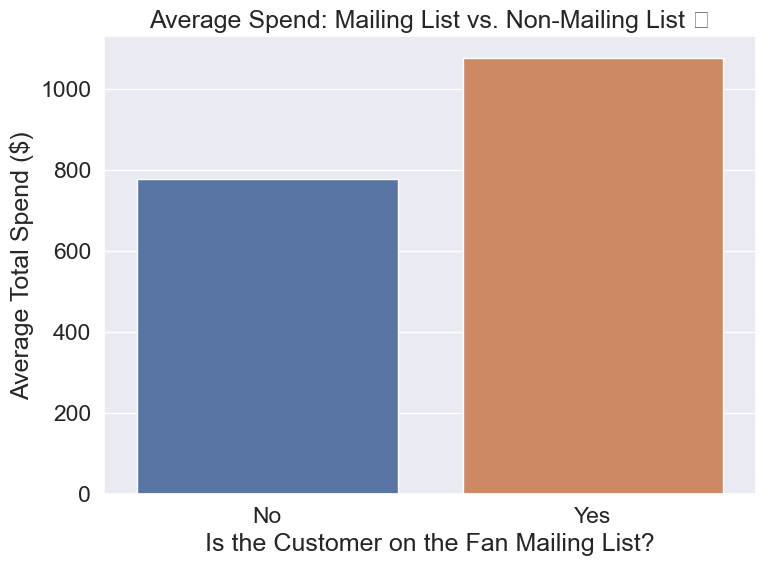

In [45]:
warriorsData = pd.read_excel("Case Study 2 Data.xlsx", sheet_name="warriors_data")

# all rev
warriorsData['Total_Revenue'] = (warriorsData['Ticket_Price'] * warriorsData['Num_Tickets_Purchased']) + warriorsData['Concession_Purchases']


#divided by mailing list status
avg_spend_by_list = warriorsData.groupby('Fan_Mailing_List')['Total_Revenue'].mean().reset_index()

print("Average Spend by whether on mailing list")
print(avg_spend_by_list)

#plot
plt.figure(figsize=(8, 6))
sns.barplot(data=avg_spend_by_list, x='Fan_Mailing_List', y='Total_Revenue')

#designn
plt.xlabel("Is the Customer on the Fan Mailing List?")
plt.ylabel("Average Total Spend ($)")
plt.title("Average Spend: Mailing List vs. Non-Mailing List 📧")
plt.tight_layout()
plt.show()

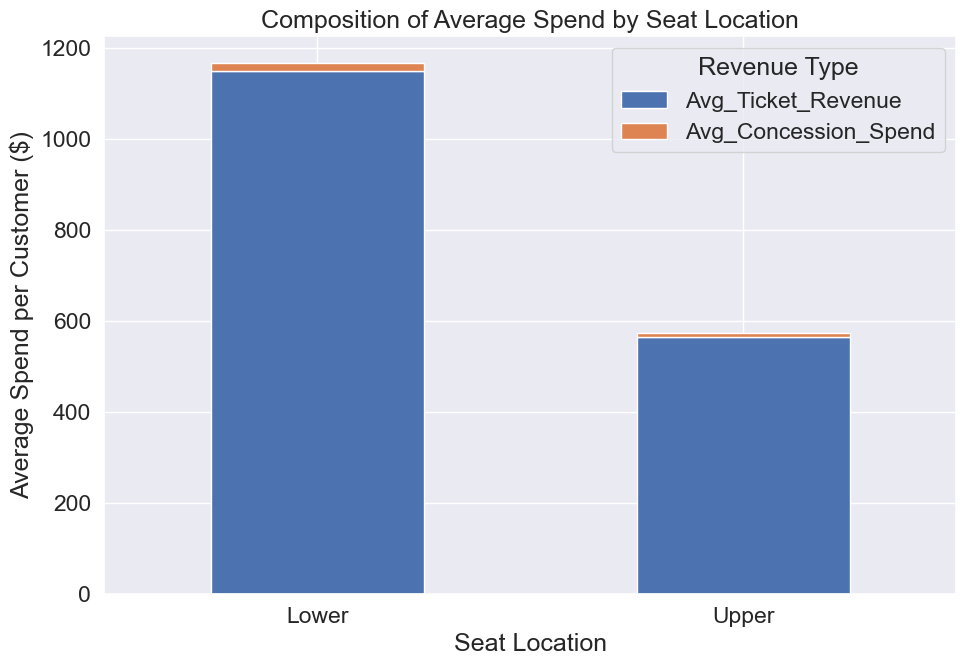

In [46]:
warriorsData = pd.read_excel("Case Study 2 Data.xlsx", sheet_name="warriors_data")
#spending by seat location
warriorsData['Ticket_Revenue'] = warriorsData['Ticket_Price'] * warriorsData['Num_Tickets_Purchased']

location_analysis = warriorsData.groupby('Seat_Location').agg(
    Avg_Ticket_Revenue=('Ticket_Revenue', 'mean'),
    Avg_Concession_Spend=('Concession_Purchases', 'mean')
).reset_index()


plot_data = location_analysis.set_index('Seat_Location')
plot_data.plot(kind='bar', stacked=True, figsize=(10, 7))

plt.xlabel("Seat Location")
plt.ylabel("Average Spend per Customer ($)")
plt.title("Composition of Average Spend by Seat Location")
plt.xticks(rotation=0) 
plt.legend(title='Revenue Type')
plt.tight_layout()
plt.show()

perhaps a facebook marketing campaign targetting older basketball fans would be good to generate more revenue